# NB4 — Task 2c: Data Augmentation
____________________________________________________________________________________________________

In NB2 we chose the **architecture**, in NB3 the **training recipe** (optimizer, learning rate, scheduler). Both stay fixed here: we only change **the training data the network sees**.

a. Visualization of each transformation (like in Lab 10), and why it makes sense for satellite images

b. MixUp and CutMix, written by hand

c. Training helpers (with MixUp / CutMix in the training loop)

d. **Ablation**: no augmentation → flips & 90° rotations → + random crop → + affine → + color jitter → + MixUp / + CutMix

e. Comparative table and plots of this notebook

f. **Task 2 comparison table**: every configuration of NB2, NB3 and NB4 (parameters, latency, peak validation accuracy, generalization gap)

g. Best configuration on the test set + checkpoint loading

Data augmentation is applied **only to the training set**. The validation and test sets are never augmented: we want to measure the accuracy on real, unmodified images.

## 0. Setup

In [1]:
import os
import json
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

ON_KAGGLE = os.path.exists("/kaggle/input")

def find_path(name, search_roots):
    # walk the search folders and return the first file / folder called `name`
    for search_root in search_roots:
        for root, dirs, files in os.walk(search_root):
            if name in dirs or name in files:
                return os.path.join(root, name)
    return None

SEARCH_ROOTS = ["/kaggle/input"] if ON_KAGGLE else ["..", "../.."]
DATA_ROOT = find_path("EuroSAT_RGB", SEARCH_ROOTS)
SPLITS_FILE = find_path("splits.json", SEARCH_ROOTS)

OUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
RES_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

NUM_WORKERS = 4 if ON_KAGGLE else 0

print("DATA_ROOT  :", DATA_ROOT)
print("SPLITS_FILE:", SPLITS_FILE)

Using device: cuda:0
DATA_ROOT  : /kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB
SPLITS_FILE: /kaggle/input/notebooks/emilioyared/aide500-nb0-setup-data-run-1010-1100/splits.json


**Datasets.** Each augmentation needs its own training `Dataset`, because the transformation is given to the dataset (Lab 10: *"the class must accept a transforms argument, which will dynamically modify the original data samples"*). The validation and test sets always use the plain transformation `ToTensor + Normalize`.

The augmentations are applied **before** `ToTensor` (on the PIL image), and `Normalize` is always the last step.

In [2]:
with open(SPLITS_FILE) as f:
    splits = json.load(f)

classes = splits["classes"]
num_classes = len(classes)
MEAN, STD = splits["mean"], splits["std"]

# plain transformation: validation, test (and training without augmentation)
plain_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=plain_transform)
valset = Subset(dataset, splits["val"])
testset = Subset(dataset, splits["test"])

# a fixed subset of the training images WITHOUT augmentation (same size as the validation set),
# used to measure the real train accuracy -> generalization gap (see section c)
rng = np.random.RandomState(0)
train_eval_set = Subset(dataset, sorted(rng.choice(splits["train"], len(splits["val"]), replace=False).tolist()))
print("train: %d | val: %d | test: %d | clean train subset: %d" % (len(splits["train"]), len(valset), len(testset), len(train_eval_set)))

BATCH_SIZE = 64
valloader = DataLoader(valset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
testloader = DataLoader(testset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
train_eval_loader = DataLoader(train_eval_set, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)


def make_trainloader(augmentations):
    # augmentations: list of transforms applied to the PIL image, before ToTensor / Normalize
    train_transform = transforms.Compose(augmentations + [
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)])
    train_dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=train_transform)
    trainset = Subset(train_dataset, splits["train"])
    return DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)

train: 18900 | val: 4050 | test: 4050 | clean train subset: 4050


**Architecture and training recipe: best of NB2 and NB3**

Same `ConfigNet` class as before. We read `NB3_best_recipe.json`, which contains both the architecture (from NB2) and the training recipe (from NB3).

In [3]:
class ConfigNet(nn.Module):
    def __init__(self, n_blocks=3, kernel_size=3, padding="same", downsample="pool", use_bn=False, n_fc=2, num_classes=10):
        super(ConfigNet, self).__init__()
        channels = [3] + [min(32 * 2 ** i, 256) for i in range(n_blocks)]  # e.g. n_blocks=3 -> [3, 32, 64, 128]
        p = kernel_size // 2 if padding == "same" else 0
        s = 2 if downsample == "stride" else 1

        blocks = []
        h = 64  # input images are 64x64
        for i in range(n_blocks):
            layers = []
            # with BatchNorm, the conv bias is useless (BN subtracts the mean and adds its own bias beta)
            layers.append(nn.Conv2d(channels[i], channels[i + 1], kernel_size, stride=s, padding=p, bias=not use_bn))
            h = (h + 2 * p - kernel_size) // s + 1           # size after the convolution
            if use_bn:
                layers.append(nn.BatchNorm2d(channels[i + 1]))
            layers.append(nn.ReLU())
            if downsample == "pool":
                layers.append(nn.MaxPool2d(2, 2))
                h = (h - 2) // 2 + 1                         # size after the pooling
            blocks.append(nn.Sequential(*layers))
        self.features = nn.Sequential(*blocks)

        assert h >= 1, "the feature maps disappear (size %d): too many blocks for this padding / kernel" % h
        self.flat_features = channels[-1] * h * h            # number of inputs of the first fc layer
        self.out_size = h

        # fully connected layers: 1 -> [flat, 10] | 2 -> [flat, 256, 10] | 3 -> [flat, 256, 128, 10]
        fc_sizes = [self.flat_features] + [256, 128][:n_fc - 1] + [num_classes]
        fc_layers = []
        for i in range(n_fc):
            fc_layers.append(nn.Linear(fc_sizes[i], fc_sizes[i + 1]))
            if i < n_fc - 1:                                 # no ReLU after the last layer (we want raw scores)
                fc_layers.append(nn.ReLU())
        self.classifier = nn.Sequential(*fc_layers)

    def forward(self, x):
        x = self.features(x)                     # [B, C, h, h]
        x = x.view(-1, self.flat_features)       # [B, C*h*h] flatten
        x = self.classifier(x)                   # [B, 10]
        return x


# check: the default configuration is exactly the baseline of NB1
net = ConfigNet()
print(net)
print("last feature maps: %dx%d | flat features: %d" % (net.out_size, net.out_size, net.flat_features))
print("parameters:", sum(p.numel() for p in net.parameters()))

ConfigNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=8192, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=10, bias=True)
  )
)
last feature maps: 8x8 | flat features: 8192
parameters: 2193226


In [4]:
RECIPE_FILE = find_path("NB3_best_recipe.json", SEARCH_ROOTS)
if RECIPE_FILE is not None:
    with open(RECIPE_FILE) as f:
        best3 = json.load(f)
    ARCH, RECIPE, n_epochs = best3["arch"], best3["recipe"], best3["n_epochs"]
    print("from NB3 (%s): %s" % (RECIPE_FILE, best3["name"]))
else:
    # fallback if NB3 results are not available
    ARCH = dict(n_blocks=5, kernel_size=3, padding="same", downsample="pool", use_bn=True, n_fc=2)
    RECIPE = {"optimizer": "Adam", "lr": 1e-3, "scheduler": "StepLR"}
    n_epochs = 25
    print("NB3_best_recipe.json not found -> default")
print("architecture:", ARCH)
print("recipe      :", RECIPE, "| epochs:", n_epochs)

net = ConfigNet(**ARCH)
print("parameters:", sum(p.numel() for p in net.parameters()))

from NB3 (/kaggle/input/notebooks/emilioyared/aide500-nb3-optimizers-lr-schedulers-run-1010-1241/results/NB3_best_recipe.json): Adam_lr0.001_StepLR
architecture: {'n_blocks': 5, 'n_fc': 2, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': True}
recipe      : {'optimizer': 'Adam', 'lr': 0.001, 'scheduler': 'StepLR'} | epochs: 25
parameters: 1244202


## a. Visualization of the augmentations

**Why augment?** In NB1–NB3 the train accuracy goes to ~100 % while the validation accuracy stops around 94–96 %: the network **memorizes** the 18,900 training images. Augmentation creates new, slightly different versions of each image at every epoch, so memorizing becomes impossible and the network has to learn what really defines the class.

**The rule (Lab 10):** a good augmentation changes the image **without changing its label**. For EuroSAT this is easier than for CIFAR-10:
- The images are taken **from above**: there is no "up" or "down". A river flipped upside-down or rotated by 90° is still a river. → **vertical flips and 90° rotations are valid** (they are not for a cat or a "6" vs "9").
- The images are **square** (64×64): a rotation by 90°/180°/270° keeps every pixel, there are no black corners.
- **Color is important** (green = vegetation, blue = water, grey = industrial): color jitter must stay **small**, especially the hue. A forest turned blue is not a forest anymore.

The transformations we use:

| Name | Transformation | What it simulates |
|---|---|---|
| flips | `RandomHorizontalFlip`, `RandomVerticalFlip`, rotation by 0/90/180/270° | the orientation of the satellite |
| crop | `RandomCrop(64, padding=4, padding_mode="reflect")` | small shifts of the tile (up to 4 px) |
| affine | `RandomAffine(degrees=15, scale=(0.9, 1.1))` | any rotation angle, small zoom |
| jitter | `ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02)` | light, season, atmosphere, sensor |

For the rotations by a multiple of 90° there is no dedicated transform: we pick one of 4 `RandomRotation((a, a))` with `RandomChoice`. `padding_mode="reflect"` fills the border with the mirror of the image instead of black (`constant`, as in Lab 10): a black border never appears in real satellite images.

In [5]:
AUG = {
    "flips": [transforms.RandomHorizontalFlip(p=0.5),
              transforms.RandomVerticalFlip(p=0.5),
              transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)])],
    "crop": [transforms.RandomCrop(64, padding=4, padding_mode="reflect")],
    "affine": [transforms.RandomAffine(degrees=15, scale=(0.9, 1.1))],
    "jitter": [transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02)],
}
for name, t in AUG.items():
    print(name, ":", t)

flips : [RandomHorizontalFlip(p=0.5), RandomVerticalFlip(p=0.5), RandomChoice(
    RandomRotation(degrees=[0.0, 0.0], interpolation=nearest, expand=False, fill=0)
    RandomRotation(degrees=[90.0, 90.0], interpolation=nearest, expand=False, fill=0)
    RandomRotation(degrees=[180.0, 180.0], interpolation=nearest, expand=False, fill=0)
    RandomRotation(degrees=[270.0, 270.0], interpolation=nearest, expand=False, fill=0)
)(p=None)]
crop : [RandomCrop(size=(64, 64), padding=4)]
affine : [RandomAffine(degrees=[-15.0, 15.0], scale=(0.9, 1.1))]
jitter : [ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.02, 0.02))]


**Let's look at the effect of each transformation.** First row: 4 original training images. Next rows: the same images after the transformation (applied 2 times, every call gives a different random result).

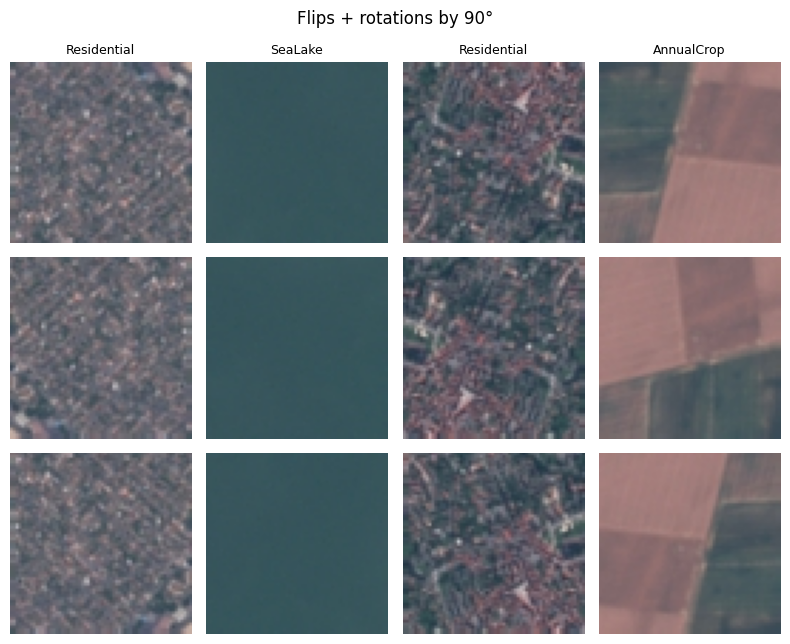

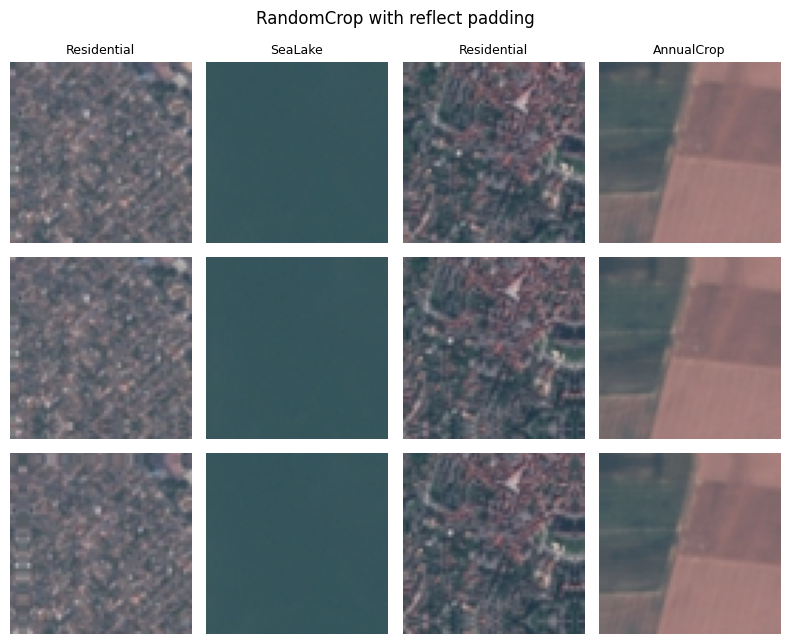

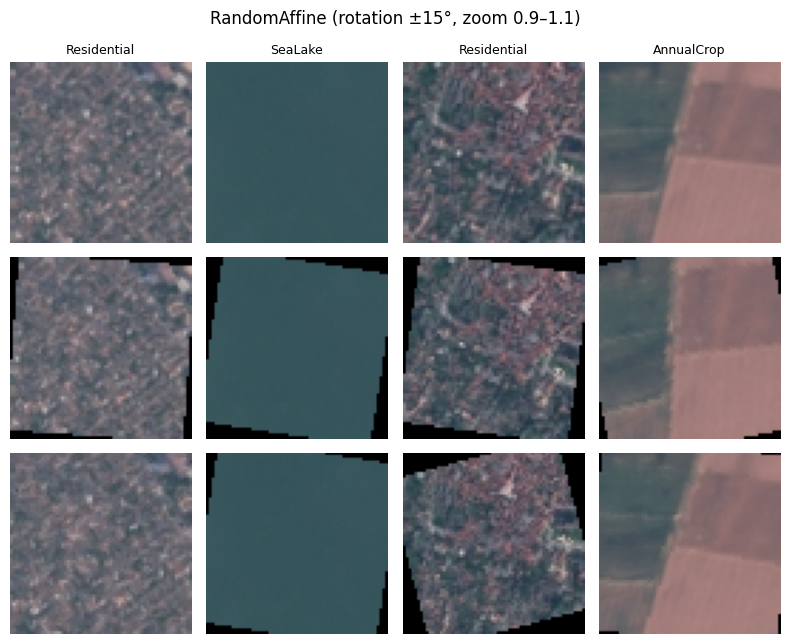

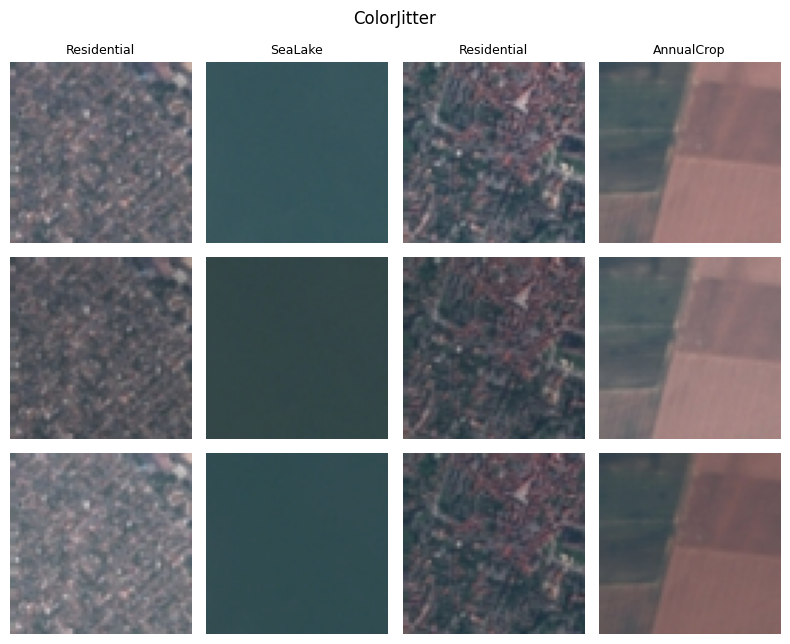

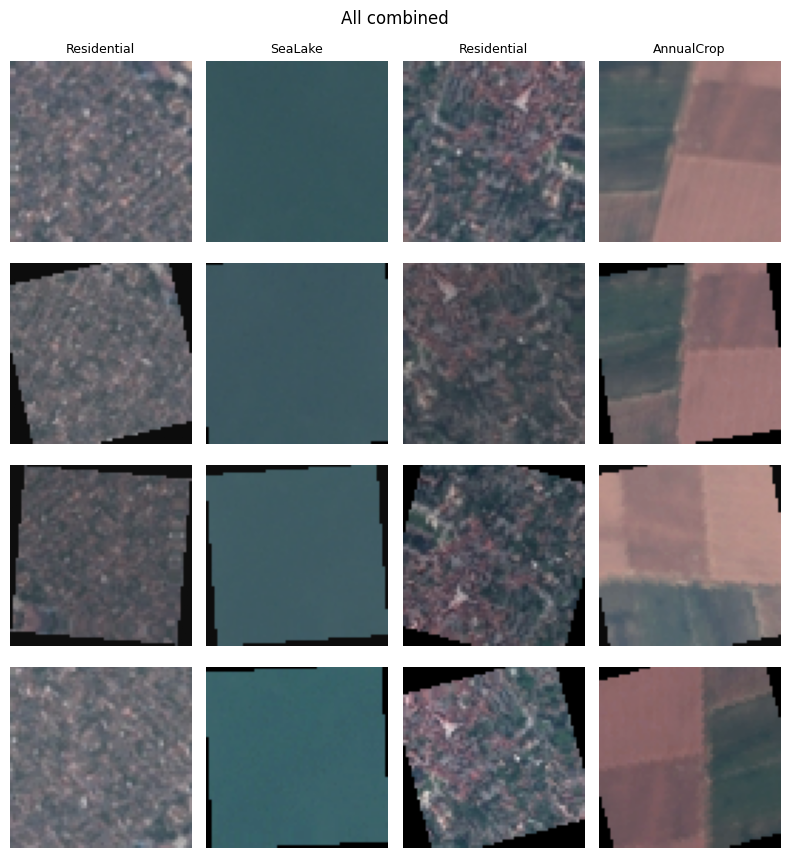

In [6]:
raw_dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT)   # no transform: PIL images
show_idx = [splits["train"][i] for i in (0, 1, 2, 3)]
show_imgs = [raw_dataset[i][0] for i in show_idx]
show_labels = [classes[raw_dataset[i][1]] for i in show_idx]


def show_transform(augmentations, title, n_repeat=2):
    t = transforms.Compose(augmentations + [transforms.ToTensor()])   # no Normalize, to display
    f = plt.figure(figsize=(8, 2.2 * (n_repeat + 1)))
    for j in range(4):
        plt.subplot(n_repeat + 1, 4, j + 1)
        plt.imshow(show_imgs[j]); plt.axis("off"); plt.title(show_labels[j], fontsize=9)
        for r in range(n_repeat):
            data = t(show_imgs[j]).numpy()
            plt.subplot(n_repeat + 1, 4, (r + 1) * 4 + j + 1)
            plt.imshow(data.swapaxes(0, 2).swapaxes(0, 1)); plt.axis("off")   # [3, H, W] -> [H, W, 3]
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


set_seed(SEED)
show_transform(AUG["flips"], "Flips + rotations by 90°")
show_transform(AUG["crop"], "RandomCrop with reflect padding")
show_transform(AUG["affine"], "RandomAffine (rotation ±15°, zoom 0.9–1.1)")
show_transform(AUG["jitter"], "ColorJitter")
show_transform(AUG["flips"] + AUG["crop"] + AUG["affine"] + AUG["jitter"], "All combined", n_repeat=3)

**Observations**
- Flips and 90° rotations give perfectly realistic images.
- `RandomAffine` with a non-multiple of 90° creates **black corners**: the only "unrealistic" transformation. We keep the angle small (±15°) to limit them.
- `ColorJitter` slightly changes the light; with `hue=0.02` the colors keep their meaning.

## b. MixUp and CutMix

These two techniques **mix two images and their labels**. They are not transforms of one image: they need 2 images of the batch, so we apply them **inside the training loop**, on the mini-batch (after the DataLoader).

For a batch `inputs`, we take a shuffled copy of the same batch `inputs[index]` (`index = torch.randperm(B)`), and a mixing coefficient $\lambda \in [0, 1]$ drawn from a Beta($\alpha$, $\alpha$) distribution.

**MixUp** (Zhang et al., 2018): a transparent superposition of the two images

$$\tilde x = \lambda \, x_a + (1 - \lambda) \, x_b$$

**CutMix** (Yun et al., 2019): a rectangle of image $b$ is pasted on image $a$. The rectangle covers a fraction $1 - \lambda$ of the image; after clipping it to the borders, $\lambda$ is recomputed from the real area of the rectangle.

**The label is mixed with the same $\lambda$.** With the cross-entropy, mixing the one-hot labels is equivalent to mixing the two losses:

$$\text{loss} = \lambda \, \text{CE}(\text{outputs}, y_a) + (1 - \lambda) \, \text{CE}(\text{outputs}, y_b)$$

Why does it help? The network is never sure at 100 %: it cannot push the scores of one class to infinity, which acts as a strong regularization (similar to label smoothing). CutMix also forces the network to recognize a class from **only a part** of the image.

| | $\alpha$ | Typical $\lambda$ |
|---|---|---|
| MixUp | 0.2 | most of the time close to 0 or 1: one image dominates |
| CutMix | 1.0 | uniform on [0, 1]: rectangles of any size |

In [7]:
MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0


def mixup_batch(inputs, labels, alpha=MIXUP_ALPHA):
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(inputs.size(0)).to(inputs.device)
    mixed = lam * inputs + (1 - lam) * inputs[index]
    return mixed, labels, labels[index], lam


def cutmix_batch(inputs, labels, alpha=CUTMIX_ALPHA):
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(inputs.size(0)).to(inputs.device)
    H, W = inputs.size(2), inputs.size(3)
    # rectangle of area (1 - lam) * H * W, centered on a random point
    cut_h, cut_w = int(H * np.sqrt(1 - lam)), int(W * np.sqrt(1 - lam))
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = np.clip(cy - cut_h // 2, 0, H), np.clip(cy + cut_h // 2, 0, H)
    x1, x2 = np.clip(cx - cut_w // 2, 0, W), np.clip(cx + cut_w // 2, 0, W)
    mixed = inputs.clone()
    mixed[:, :, y1:y2, x1:x2] = inputs[index, :, y1:y2, x1:x2]
    lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)   # real proportion of image a after clipping
    return mixed, labels, labels[index], lam

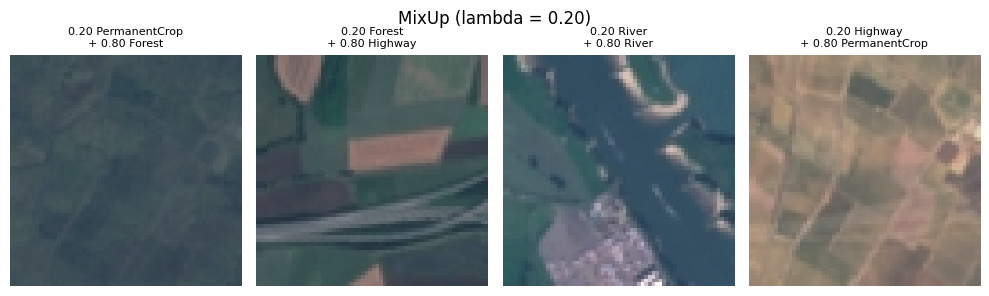

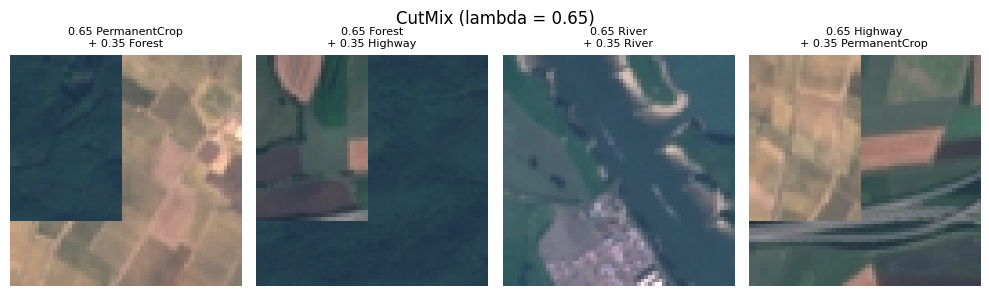

In [8]:
# visualize on 4 training images (without Normalize, to display them)
vis_set = Subset(torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=transforms.ToTensor()), splits["train"])
images, labels = next(iter(DataLoader(vis_set, batch_size=4, shuffle=True)))

for title, mix_fn, alpha in [("MixUp", mixup_batch, 0.4), ("CutMix", cutmix_batch, 1.0)]:
    set_seed(1)
    mixed, labels_a, labels_b, lam = mix_fn(images, labels, alpha)
    f = plt.figure(figsize=(10, 3))
    for j in range(4):
        plt.subplot(1, 4, j + 1)
        plt.imshow(mixed[j].numpy().swapaxes(0, 2).swapaxes(0, 1)); plt.axis("off")
        plt.title("%.2f %s\n+ %.2f %s" % (lam, classes[labels_a[j]], 1 - lam, classes[labels_b[j]]), fontsize=8)
    plt.suptitle("%s (lambda = %.2f)" % (title, lam))
    plt.tight_layout()
    plt.show()

(For the display we use $\alpha = 0.4$ for MixUp so that the mixing is visible; in training we use $\alpha = 0.2$.)

## c. Training helpers

Same functions as in NB3, with two changes:

1. `train_one_epoch` has a `mix` argument: `None`, `"mixup"` or `"cutmix"`. With a mix, the loss is $\lambda \, \text{CE}(y_a) + (1-\lambda) \, \text{CE}(y_b)$, and the train accuracy counts a prediction as $\lambda$ correct if it is $y_a$ and $(1-\lambda)$ correct if it is $y_b$.

2. **Generalization gap.** With augmentation, the train accuracy measured during training is computed on **augmented** images (harder than the real ones), so `train acc − val acc` would underestimate the overfitting. At each epoch we therefore also evaluate the network on a fixed subset of **4,050 training images without augmentation** ("clean train accuracy"):

$$\text{gap} = \text{clean train acc} - \text{val acc} \quad \text{(at the best epoch)}$$

Without augmentation, the clean train accuracy and the train accuracy are the same thing (up to the subset, and BatchNorm being in eval mode).

In [9]:
def make_optimizer(name, params, lr):
    if name == "SGD":
        return optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)
    if name == "Adam":
        return optim.Adam(params, lr=lr)
    if name == "AdamW":
        return optim.AdamW(params, lr=lr, weight_decay=0.01)
    raise ValueError(name)

In [10]:
def train_one_epoch(net, loader, criterion, optimizer, batch_scheduler=None, mix=None):
    net.train()
    running_loss, correct, total = 0.0, 0.0, 0
    for i, data in enumerate(loader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)
        if mix == "mixup":
            inputs, labels_a, labels_b, lam = mixup_batch(inputs, labels)
        elif mix == "cutmix":
            inputs, labels_a, labels_b, lam = cutmix_batch(inputs, labels)

        optimizer.zero_grad()
        outputs = net(inputs)
        if mix is None:
            loss = criterion(outputs, labels)
        else:
            loss = lam * criterion(outputs, labels_a) + (1 - lam) * criterion(outputs, labels_b)
        loss.backward()
        optimizer.step()
        if batch_scheduler is not None:
            batch_scheduler.step()

        running_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        if mix is None:
            correct += (predicted == labels).sum().item()
        else:
            correct += lam * (predicted == labels_a).sum().item() + (1 - lam) * (predicted == labels_b).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total

In [11]:
def evaluate(net, loader, criterion):
    net.eval()
    running_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for data in loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = net(images)
            running_loss += criterion(outputs, labels).item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            all_preds.append(predicted.cpu())
            all_labels.append(labels.cpu())
            total += labels.size(0)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    acc = 100.0 * (all_preds == all_labels).mean()
    per_class_acc = [100.0 * (all_preds[all_labels == c] == c).mean() for c in range(num_classes)]
    return running_loss / total, acc, per_class_acc, all_preds, all_labels


def measure_latency(net, n_runs=100):
    net.eval()
    x = torch.randn(1, 3, 64, 64).to(device)
    with torch.no_grad():
        for _ in range(10):  # warm-up
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()  # wait for the GPU to finish before reading the time
        start = time.time()
        for _ in range(n_runs):
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - start) / n_runs * 1000  # milliseconds per image

In [12]:
criterion = nn.CrossEntropyLoss()

all_histories = {}
all_summaries = {}
all_setups = {}


def make_scheduler(name, optimizer, lr, steps_per_epoch):
    # same schedulers as NB3: returns (epoch_scheduler, batch_scheduler)
    if name == "none":
        return None, None
    if name == "StepLR":
        return optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1), None
    if name == "Cosine":
        return optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs), None
    if name == "OneCycle":
        return None, optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, epochs=n_epochs, steps_per_epoch=steps_per_epoch)
    raise ValueError(name)


def run_experiment(name, aug_names, mix=None):
    set_seed(SEED)
    augmentations = [t for a in aug_names for t in AUG[a]]
    trainloader = make_trainloader(augmentations)
    net = ConfigNet(**ARCH).to(device)
    optimizer = make_optimizer(RECIPE["optimizer"], net.parameters(), RECIPE["lr"])
    epoch_scheduler, batch_scheduler = make_scheduler(RECIPE["scheduler"], optimizer, RECIPE["lr"], len(trainloader))
    ckpt_path = os.path.join(CKPT_DIR, "NB4_%s.pth" % name)
    print('===== %s | augmentations: %s | mix: %s =====' % (name, "+".join(aug_names) or "none", mix))

    history = {"train_loss": [], "train_acc": [], "clean_train_acc": [], "val_loss": [], "val_acc": [], "val_per_class_acc": [], "epoch_time": []}
    best_val_acc = 0.0
    for epoch in range(n_epochs):
        start = time.time()
        train_loss, train_acc = train_one_epoch(net, trainloader, criterion, optimizer, batch_scheduler, mix)
        _, clean_train_acc, _, _, _ = evaluate(net, train_eval_loader, criterion)
        val_loss, val_acc, val_per_class_acc, _, _ = evaluate(net, valloader, criterion)
        if epoch_scheduler is not None:
            epoch_scheduler.step()
        epoch_time = time.time() - start

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["clean_train_acc"].append(clean_train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_per_class_acc"].append(val_per_class_acc)
        history["epoch_time"].append(epoch_time)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(net.state_dict(), ckpt_path)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print('[epoch %2d] train loss: %.3f | train acc: %.2f %% | clean train acc: %.2f %% | val loss: %.3f | val acc: %.2f %% | %.1f s' %
                  (epoch + 1, train_loss, train_acc, clean_train_acc, val_loss, val_acc, epoch_time))

    best_epoch = int(np.argmax(history["val_acc"]))
    summary = {
        "name": name, "augmentations": "+".join(aug_names) or "none", "mix": mix or "none",
        "best_val_acc": best_val_acc,
        "best_epoch": best_epoch + 1,
        "final_val_acc": history["val_acc"][-1],
        "min_val_loss": min(history["val_loss"]),
        "gen_gap": history["clean_train_acc"][best_epoch] - history["val_acc"][best_epoch],
        "train_time_s": sum(history["epoch_time"]),
    }
    print('-> best val acc: %.2f %% (epoch %d) | gap: %.2f | min val loss: %.3f' %
          (best_val_acc, best_epoch + 1, summary["gen_gap"], summary["min_val_loss"]))

    all_histories[name] = history
    all_summaries[name] = summary
    all_setups[name] = {"augmentations": list(aug_names), "mix": mix}
    with open(os.path.join(RES_DIR, "NB4_%s_history.json" % name), "w") as f:
        json.dump(history, f)
    return summary

## d. Ablation study

We add the augmentations **one at a time** (cumulative), so that each step shows the effect of one more transformation:

1. `none`: no augmentation (the NB3 recipe, retrained here as the reference)
2. `flips`: horizontal / vertical flips + rotations by 90°
3. `flips+crop`
4. `flips+crop+affine`
5. `flips+crop+affine+jitter`

Then, on top of the **best** of these 5 (by validation accuracy):

6. `+ MixUp`
7. `+ CutMix`

What we expect: the train accuracy decreases (the task is harder), the gap decreases, and the validation accuracy increases as long as the augmentations stay realistic.

In [13]:
ABLATION = [
    ("none", []),
    ("flips", ["flips"]),
    ("flips_crop", ["flips", "crop"]),
    ("flips_crop_affine", ["flips", "crop", "affine"]),
    ("flips_crop_affine_jitter", ["flips", "crop", "affine", "jitter"]),
]
for name, aug_names in ABLATION:
    run_experiment(name, aug_names)

===== none | augmentations: none | mix: None =====
[epoch  1] train loss: 0.825 | train acc: 70.52 % | clean train acc: 68.10 % | val loss: 1.058 | val acc: 65.85 % | 169.7 s
[epoch  5] train loss: 0.284 | train acc: 90.31 % | clean train acc: 90.47 % | val loss: 0.375 | val acc: 87.19 % | 18.5 s
[epoch 10] train loss: 0.159 | train acc: 94.39 % | clean train acc: 91.36 % | val loss: 0.396 | val acc: 87.63 % | 17.5 s
[epoch 15] train loss: 0.047 | train acc: 98.44 % | clean train acc: 99.26 % | val loss: 0.140 | val acc: 95.21 % | 17.3 s
[epoch 20] train loss: 0.033 | train acc: 98.94 % | clean train acc: 99.36 % | val loss: 0.163 | val acc: 95.16 % | 17.7 s
[epoch 25] train loss: 0.023 | train acc: 99.25 % | clean train acc: 99.78 % | val loss: 0.147 | val acc: 95.83 % | 17.6 s
-> best val acc: 95.85 % (epoch 24) | gap: 3.90 | min val loss: 0.137
===== flips | augmentations: flips | mix: None =====
[epoch  1] train loss: 0.814 | train acc: 70.75 % | clean train acc: 72.52 % | val loss

In [14]:
best_aug = max([n for n, _ in ABLATION], key=lambda n: all_summaries[n]["best_val_acc"])
BEST_AUG_NAMES = all_setups[best_aug]["augmentations"]
print("best augmentation without mixing: %s (best val acc %.2f %%)" % (best_aug, all_summaries[best_aug]["best_val_acc"]))

run_experiment(best_aug + "_mixup", BEST_AUG_NAMES, mix="mixup")
run_experiment(best_aug + "_cutmix", BEST_AUG_NAMES, mix="cutmix")

best augmentation without mixing: flips_crop (best val acc 96.44 %)
===== flips_crop_mixup | augmentations: flips+crop | mix: mixup =====
[epoch  1] train loss: 1.206 | train acc: 60.77 % | clean train acc: 73.01 % | val loss: 0.822 | val acc: 71.88 % | 21.0 s
[epoch  5] train loss: 0.747 | train acc: 78.42 % | clean train acc: 86.27 % | val loss: 0.436 | val acc: 85.09 % | 20.8 s
[epoch 10] train loss: 0.614 | train acc: 82.36 % | clean train acc: 91.36 % | val loss: 0.335 | val acc: 89.51 % | 21.0 s
[epoch 15] train loss: 0.550 | train acc: 85.20 % | clean train acc: 96.67 % | val loss: 0.196 | val acc: 95.38 % | 21.0 s
[epoch 20] train loss: 0.478 | train acc: 87.30 % | clean train acc: 96.49 % | val loss: 0.172 | val acc: 94.99 % | 20.6 s
[epoch 25] train loss: 0.505 | train acc: 86.59 % | clean train acc: 97.04 % | val loss: 0.165 | val acc: 96.02 % | 20.2 s
-> best val acc: 96.52 % (epoch 23) | gap: 1.21 | min val loss: 0.137
===== flips_crop_cutmix | augmentations: flips+crop | 

{'name': 'flips_crop_cutmix',
 'augmentations': 'flips+crop',
 'mix': 'cutmix',
 'best_val_acc': np.float64(95.18518518518519),
 'best_epoch': 25,
 'final_val_acc': np.float64(95.18518518518519),
 'min_val_loss': 0.20903068807390002,
 'gen_gap': np.float64(0.9135802469135683),
 'train_time_s': 516.4908165931702}

## e. Comparative table and plots

In [15]:
print('%-34s %-28s %8s %13s %14s %8s %13s %10s' % ('run', 'augmentations', 'mix', 'best val acc', 'final val acc', 'gap', 'min val loss', 'time (s)'))
print('-' * 135)
for name, s in all_summaries.items():
    print('%-34s %-28s %8s %12.2f%% %13.2f%% %8.2f %13.3f %10.0f' % (name, s["augmentations"], s["mix"], s["best_val_acc"],
          s["final_val_acc"], s["gen_gap"], s["min_val_loss"], s["train_time_s"]))

with open(os.path.join(RES_DIR, "NB4_summaries.json"), "w") as f:
    json.dump({"arch": ARCH, "recipe": RECIPE, "summaries": all_summaries, "setups": all_setups}, f, indent=2)

run                                augmentations                     mix  best val acc  final val acc      gap  min val loss   time (s)
---------------------------------------------------------------------------------------------------------------------------------------
none                               none                             none        95.85%         95.83%     3.90         0.137        606
flips                              flips                            none        96.30%         96.15%     1.85         0.109        441
flips_crop                         flips+crop                       none        96.44%         96.27%     1.43         0.107        501
flips_crop_affine                  flips+crop+affine                none        96.10%         95.93%     0.96         0.121        516
flips_crop_affine_jitter           flips+crop+affine+jitter         none        95.65%         95.65%     0.99         0.131        659
flips_crop_mixup                   flips+crop   

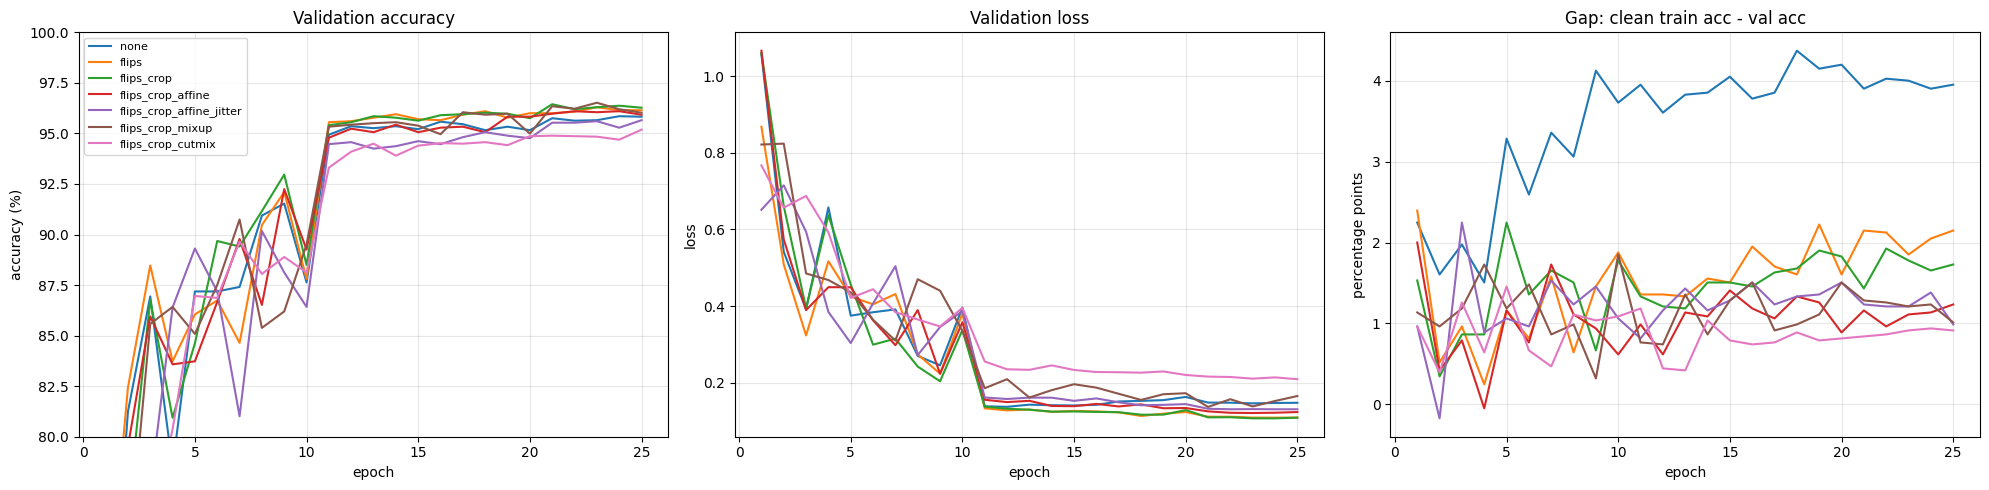

In [16]:
epochs = range(1, n_epochs + 1)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for name, h in all_histories.items():
    axes[0].plot(epochs, h["val_acc"], label=name)
    axes[1].plot(epochs, h["val_loss"], label=name)
    axes[2].plot(epochs, np.array(h["clean_train_acc"]) - np.array(h["val_acc"]), label=name)
axes[0].set_title("Validation accuracy"); axes[0].set_ylabel("accuracy (%)"); axes[0].set_ylim(80, 100)
axes[1].set_title("Validation loss"); axes[1].set_ylabel("loss")
axes[2].set_title("Gap: clean train acc - val acc"); axes[2].set_ylabel("percentage points")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

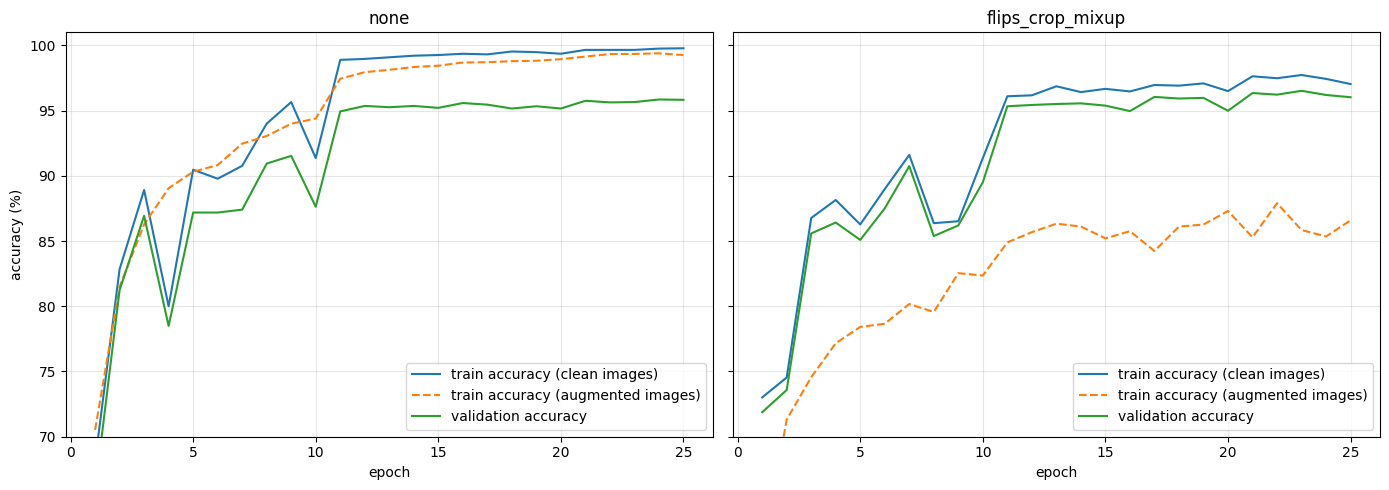

In [17]:
# overfitting with and without augmentation: clean train accuracy vs validation accuracy
best4 = max(all_summaries.keys(), key=lambda n: all_summaries[n]["best_val_acc"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, name in zip(axes, ["none", best4]):
    h = all_histories[name]
    ax.plot(epochs, h["clean_train_acc"], label="train accuracy (clean images)")
    ax.plot(epochs, h["train_acc"], "--", label="train accuracy (augmented images)")
    ax.plot(epochs, h["val_acc"], label="validation accuracy")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylim(70, 101); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel("accuracy (%)")
plt.tight_layout()
plt.show()

## f. Task 2 comparison table

All the configurations of Task 2 (NB2: architecture, NB3: optimizer / learning rate / scheduler, NB4: augmentation) in one table:

- **params**: number of trainable parameters
- **latency**: inference time for **one** image (batch of 1) on the GPU, in ms
- **peak val acc**: best validation accuracy during training
- **gap**: train accuracy − validation accuracy at the best epoch (for NB4: **clean** train accuracy)

All NB3 and NB4 runs share the same architecture, so they have the same parameters and latency (measured here). The NB2 values are read from `NB2_summaries.json`.

In [18]:
arch_params = sum(p.numel() for p in ConfigNet(**ARCH).parameters())
arch_latency = measure_latency(ConfigNet(**ARCH).to(device))

rows = []   # (notebook, run, params, latency, peak val acc, gap)
NB2_FILE = find_path("NB2_summaries.json", SEARCH_ROOTS)
if NB2_FILE is not None:
    with open(NB2_FILE) as f:
        for name, s in json.load(f)["summaries"].items():
            rows.append(("NB2", name, s["params"], s["latency_ms"], s["best_val_acc"], s["gen_gap"]))
NB3_FILE = find_path("NB3_summaries.json", SEARCH_ROOTS)
if NB3_FILE is not None:
    with open(NB3_FILE) as f:
        for name, s in json.load(f)["summaries"].items():
            rows.append(("NB3", name, arch_params, arch_latency, s["best_val_acc"], s["gen_gap"]))
for name, s in all_summaries.items():
    rows.append(("NB4", name, arch_params, arch_latency, s["best_val_acc"], s["gen_gap"]))

print('%-4s %-34s %10s %13s %13s %8s' % ('NB', 'configuration', 'params', 'latency (ms)', 'peak val acc', 'gap'))
print('-' * 88)
for r in rows:
    print('%-4s %-34s %10d %13.3f %12.2f%% %8.2f' % r)

with open(os.path.join(RES_DIR, "Task2_comparison.json"), "w") as f:
    json.dump([dict(zip(["notebook", "run", "params", "latency_ms", "best_val_acc", "gen_gap"], r)) for r in rows], f, indent=2)

NB   configuration                          params  latency (ms)  peak val acc      gap
----------------------------------------------------------------------------------------
NB2  baseline                              2193226         0.380        91.11%     8.87
NB2  depth_2blocks                         4216522         0.302        86.74%    13.21
NB2  depth_4blocks                         1439818         0.471        92.37%     7.32
NB2  depth_5blocks                         1243466         0.635        93.04%     6.17
NB2  fc_1layers                             175178         0.338        90.74%     9.21
NB2  fc_3layers                            2224842         0.438        91.11%     8.79
NB2  kernel_5x5                            2358602         0.535        89.16%    10.81
NB2  kernel_7x7                            2606666         0.771        79.95%    15.87
NB2  padding_valid                         1275722         0.391        89.21%    10.51
NB2  downsample_stride         

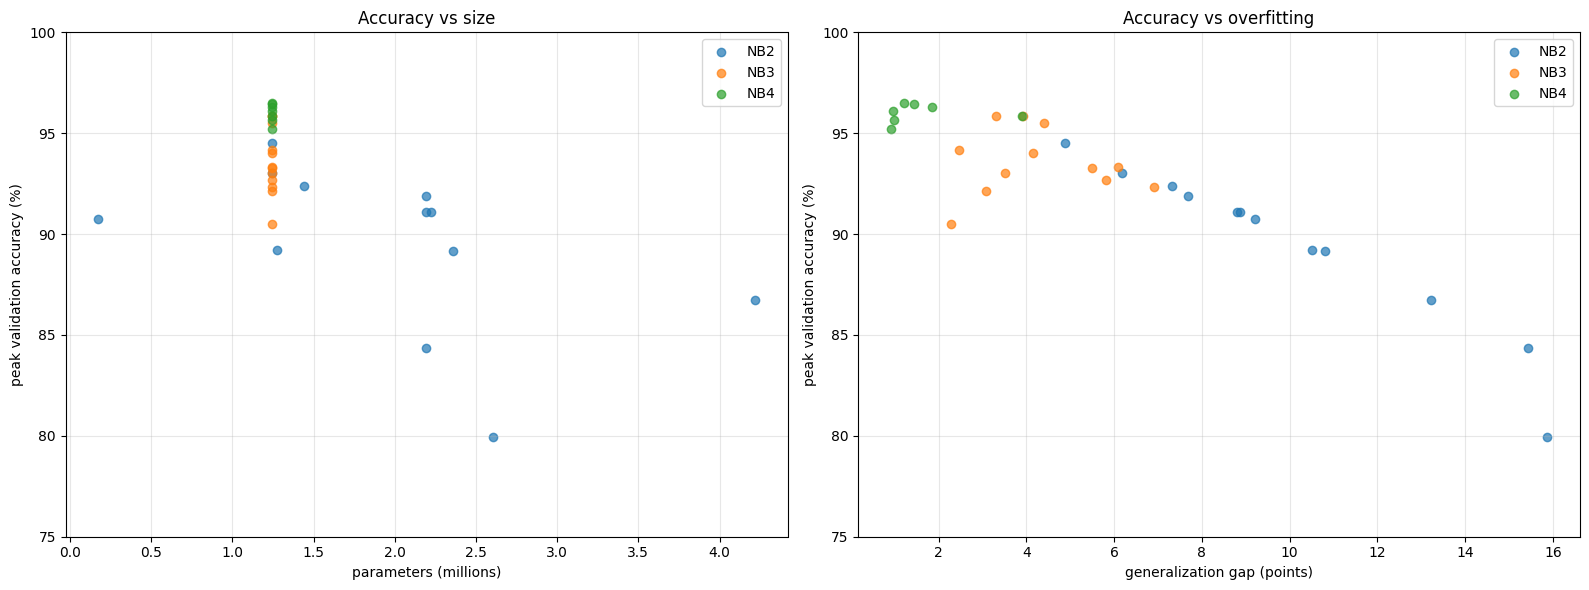

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
colors = {"NB2": "tab:blue", "NB3": "tab:orange", "NB4": "tab:green"}
for nb_name in colors:
    sel = [r for r in rows if r[0] == nb_name]
    if len(sel) == 0:
        continue
    ax1.scatter([r[2] / 1e6 for r in sel], [r[4] for r in sel], c=colors[nb_name], label=nb_name, alpha=0.7)
    ax2.scatter([r[5] for r in sel], [r[4] for r in sel], c=colors[nb_name], label=nb_name, alpha=0.7)
ax1.set_xlabel("parameters (millions)"); ax1.set_ylabel("peak validation accuracy (%)"); ax1.set_title("Accuracy vs size")
ax2.set_xlabel("generalization gap (points)"); ax2.set_ylabel("peak validation accuracy (%)"); ax2.set_title("Accuracy vs overfitting")
for ax in (ax1, ax2):
    ax.set_ylim(75, 100); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## g. Best configuration on the test set

The best NB4 run (on the **validation** set) is the final from-scratch model of Task 2. We evaluate it once on the test set.

In [20]:
best_name = max(all_summaries.keys(), key=lambda n: all_summaries[n]["best_val_acc"])
print("best run:", best_name, all_setups[best_name])

best_net = ConfigNet(**ARCH).to(device)
best_net.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB4_%s.pth" % best_name), map_location=device))
test_loss, test_acc, test_per_class_acc, test_preds, test_labels = evaluate(best_net, testloader, criterion)

print('Accuracy of the network on the %d test images: %.2f %%' % (len(testset), test_acc))
for c in range(num_classes):
    print('Accuracy of %22s : %.1f %%' % (classes[c], test_per_class_acc[c]))

# the "none" run is the NB3 recipe retrained here: its test accuracy is the reference without augmentation
ref_net = ConfigNet(**ARCH).to(device)
ref_net.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB4_none.pth"), map_location=device))
_, ref_test_acc, _, _, _ = evaluate(ref_net, testloader, criterion)
print('\nwithout augmentation ("none"): %.2f %% -> with %s: %.2f %%' % (ref_test_acc, best_name, test_acc))

with open(os.path.join(RES_DIR, "NB4_best_recipe.json"), "w") as f:
    json.dump({"name": best_name, "arch": ARCH, "recipe": RECIPE, "n_epochs": n_epochs,
               "augmentations": all_setups[best_name]["augmentations"], "mix": all_setups[best_name]["mix"],
               "test_acc": test_acc, "test_acc_no_aug": ref_test_acc,
               "params": arch_params, "latency_ms": arch_latency}, f, indent=2)

best run: flips_crop_mixup {'augmentations': ['flips', 'crop'], 'mix': 'mixup'}
Accuracy of the network on the 4050 test images: 97.04 %
Accuracy of             AnnualCrop : 95.6 %
Accuracy of                 Forest : 98.9 %
Accuracy of   HerbaceousVegetation : 95.3 %
Accuracy of                Highway : 97.9 %
Accuracy of             Industrial : 98.7 %
Accuracy of                Pasture : 98.0 %
Accuracy of          PermanentCrop : 92.3 %
Accuracy of            Residential : 99.3 %
Accuracy of                  River : 94.4 %
Accuracy of                SeaLake : 99.6 %

without augmentation ("none"): 96.54 % -> with flips_crop_mixup: 97.04 %


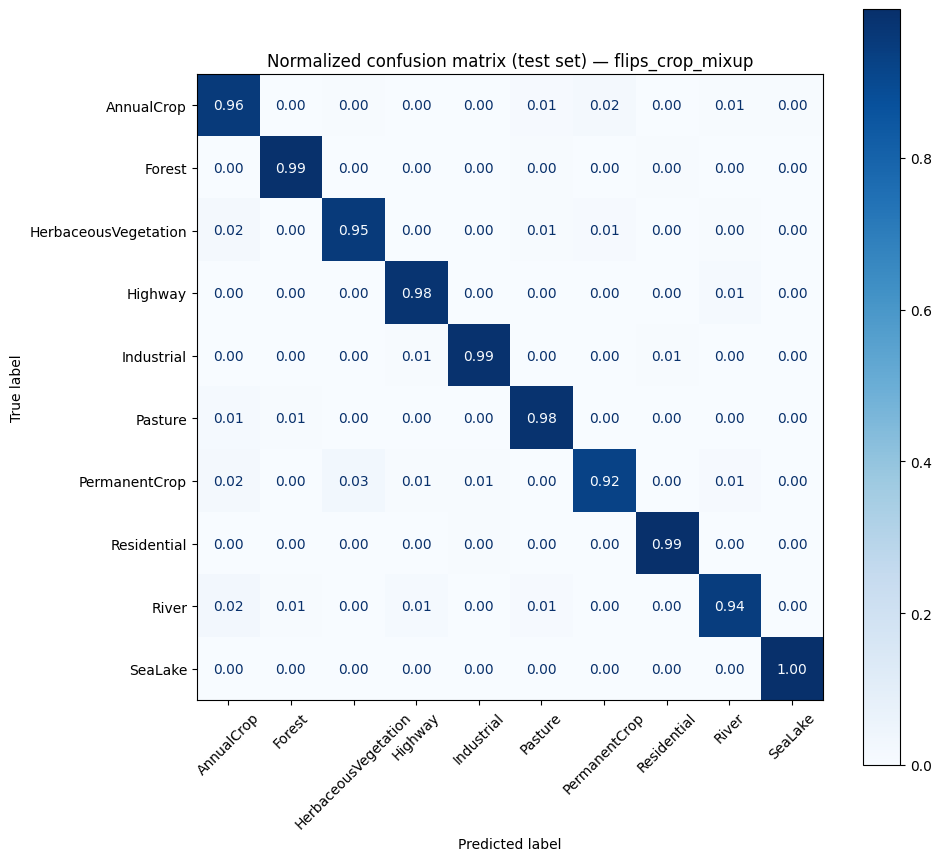

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(test_labels, test_preds, normalize="true")
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45)
ax.set_title("Normalized confusion matrix (test set) — %s" % best_name)
plt.tight_layout()
plt.show()

## h. Load a saved checkpoint and test it on unseen mini-batches

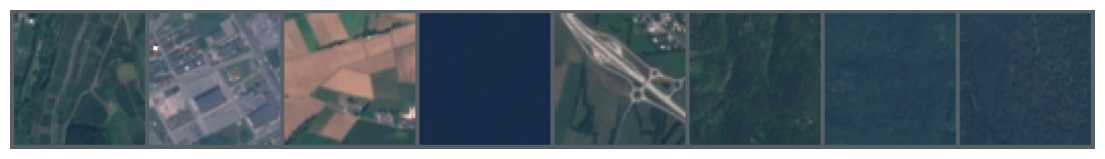

GroundTruth:  PermanentCrop | Industrial | AnnualCrop | SeaLake | Highway | Forest | Forest | Forest
Predicted  :  PermanentCrop (0.87) | Industrial (0.90) | AnnualCrop (0.40) | SeaLake (0.97) | Highway (0.96) | Forest (0.96) | Forest (0.98) | Forest (0.98)


In [22]:
NAME = best_name   # any run of this notebook, e.g. "flips"

trainednet = ConfigNet(**ARCH)
trainednet.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB4_%s.pth" % NAME), map_location="cpu"))
trainednet.eval()

def imshow(img):
    img = img * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    npimg = img.clamp(0, 1).numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")

demo_loader = DataLoader(testset, batch_size=8, shuffle=True)
images, labels = next(iter(demo_loader))
with torch.no_grad():
    outputs = trainednet(images)
    softmax = nn.Softmax(dim=1)
    probs = softmax(outputs)
    conf, predicted = torch.max(probs, 1)

plt.figure(figsize=(14, 3))
imshow(torchvision.utils.make_grid(images, nrow=8))
plt.show()
print('GroundTruth: ', ' | '.join('%s' % classes[labels[j]] for j in range(8)))
print('Predicted  : ', ' | '.join('%s (%.2f)' % (classes[predicted[j]], conf[j]) for j in range(8)))